# El grupo que más compra es el que menos descuento aguanta

Un distribuidor B2B da la misma promoción a todos sus clientes. La pregunta es a quién se le
puede descontar, cuánto y a cambio de qué. Este notebook reproduce el método de principio a
fin: de las líneas de factura a una fila por cliente, de ahí a cuatro grupos, un techo de
descuento por grupo y la rentabilidad de un rappel por crecimiento.

**Los datos son sintéticos.** Salen de `promociones/datos.py` con una semilla fija e imitan la
forma de una cartera real (cola larga de volumen, margen independiente del tamaño, un grupo
pequeño que crece deprisa), no sus cifras. El caso contado está en
[alejandrocamposlamas.com](https://alejandrocamposlamas.com/portfolio/el-grupo-que-mas-compra/).

In [1]:
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans

from promociones import segmentar as sg
from promociones import techo as tc
from promociones.abt import construir_abt
from promociones.datos import ANIO, generar_facturas

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
TINTA, SUAVE, ACENTO, LINEA, FONDO = "#16161a", "#55555f", "#9a3412", "#dededa", "#fbfbf9"
plt.rcParams.update({"figure.facecolor": FONDO, "axes.facecolor": FONDO,
                     "axes.edgecolor": LINEA, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})

## 1. De la factura al cliente

La facturación llega como líneas: pedido, cliente, fecha, categoría, importe y coste. El
análisis necesita una fila por cliente con seis variables. La consulta está en
`sql/abt_clientes.sql` y corre sobre SQLite, la base que viene con Python.

In [2]:
facturas = generar_facturas()
abt = construir_abt(facturas, ANIO)
print(f"{len(facturas):,} líneas de factura -> {len(abt):,} clientes con compras en {ANIO}")
facturas.head()

166,229 líneas de factura -> 1,285 clientes con compras en 2025


,pedido,cliente,fecha,categoria,importe,coste
0,C0140-2024-028,C0140,2024-09-07,cat_11,"1,296.660","1,176.850"
1,C0148-2024-047,C0148,2024-02-19,cat_02,390.140,344.230
2,C1257-2025-008,C1257,2025-04-17,cat_09,344.350,259.140
3,C0408-2024-001,C0408,2024-12-06,cat_10,"1,101.520",691.800
4,C0527-2025-046,C0527,2025-12-06,cat_03,126.950,83.750


In [3]:
abt.head()

,cliente,volumen,frecuencia,ticket_medio,margen,margen_pct,n_categorias,tendencia
0,C0001,"49,415.520",63,784.373,"7,567.600",0.153,5,1.092
1,C0002,"321,330.920",57,"5,637.385","10,381.590",0.032,5,0.954
2,C0003,"237,192.360",50,"4,743.847","23,697.290",0.100,3,1.039
3,C0004,"309,293.430",49,"6,312.111","32,229.460",0.104,3,0.589
4,C0005,"278,702.780",65,"4,287.735","9,239.900",0.033,4,0.866


In [4]:
abt[["volumen", "frecuencia", "ticket_medio", "margen_pct", "n_categorias", "tendencia"]].describe()

,volumen,frecuencia,ticket_medio,margen_pct,n_categorias,tendencia
count,"1,285.000","1,285.000","1,285.000","1,285.000","1,285.000","1,285.000"
mean,"203,112.608",32.871,"4,543.972",0.186,4.156,1.048
std,"467,213.852",25.826,"8,030.838",0.111,2.525,0.312
min,276.950,2.000,30.772,-0.086,1.000,0.487
25%,"10,757.420",9.000,763.960,0.096,2.000,0.879
50%,"37,053.640",18.000,"1,941.183",0.173,4.000,1.000
75%,"171,798.950",60.000,"4,734.969",0.265,5.000,1.137
max,"6,008,144.260",88.000,"78,027.848",0.559,12.000,3.016


El volumen tiene una cola muy larga: la media se va por encima del tercer cuartil. Por eso
las variables de escala entran al modelo en logaritmo y con un escalado por mediana y rango
intercuartílico, que no se deja arrastrar por los pocos clientes enormes. El margen entra como
porcentaje sobre venta: el margen en euros repite casi lo mismo que el volumen.

## 2. Cuántos grupos

Se prueba de 2 a 10 grupos y se mira lo que dicen las medidas habituales.

In [5]:
x, escalador = sg.preparar(abt)
barrido = sg.barrido_k(x)
barrido

,inercia,silueta,calinski_harabasz,grupo_menor
k,,,,
2,"3,226.365",0.274,468.190,506
3,"2,562.500",0.297,460.576,142
4,"2,047.283",0.279,491.481,128
5,"1,806.393",0.244,460.114,98
6,"1,620.263",0.244,439.449,50
7,"1,476.146",0.238,422.452,54
8,"1,380.696",0.233,399.427,47
9,"1,312.258",0.216,375.756,47
10,"1,251.334",0.208,356.890,47


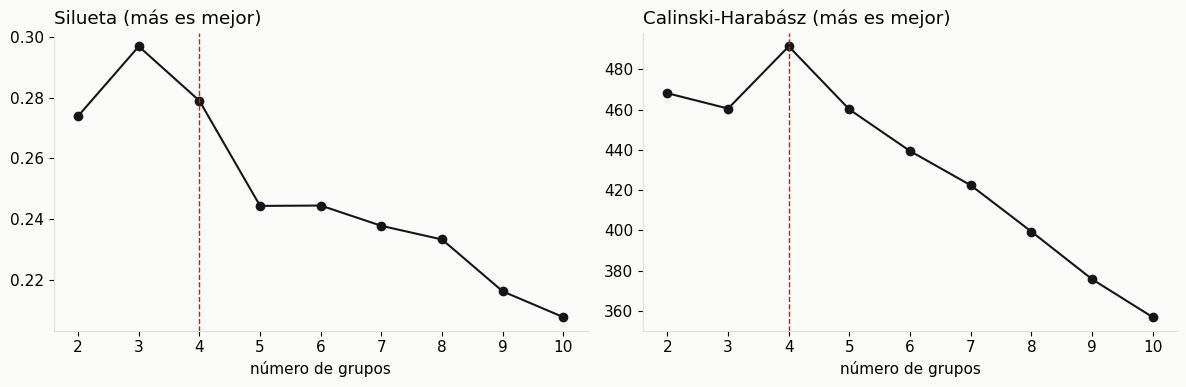

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(barrido.index, barrido.silueta, marker="o", color=TINTA)
a1.set_title("Silueta (más es mejor)", loc="left")
a2.plot(barrido.index, barrido.calinski_harabasz, marker="o", color=TINTA)
a2.set_title("Calinski-Harabász (más es mejor)", loc="left")
for a in (a1, a2):
    a.axvline(4, color=ACENTO, ls="--", lw=1)
    a.set_xlabel("número de grupos")
plt.tight_layout()

In [7]:
print("La silueta prefiere k =", barrido.silueta.idxmax())
print("Calinski-Harabász prefiere k =", barrido.calinski_harabasz.idxmax())

La silueta prefiere k = 3
Calinski-Harabász prefiere k = 4


Las medidas no coinciden entre sí, y ninguna responde a la pregunta de negocio: si con menos
grupos ventas puede hacer ofertas distintas a quien las necesita distintas. Se mira dónde cae el
volumen de cada uno de los cuatro grupos finales cuando se fuerza a dos o a tres.

In [8]:
km = sg.ajustar(x, k=4)
segmento = sg.etiquetar(abt, km.labels_)

for k in (2, 3):
    grupos = KMeans(k, random_state=sg.SEMILLA, n_init=10).fit_predict(x)
    reparto = pd.crosstab(segmento, grupos, values=abt.volumen, aggfunc="sum", normalize="index")
    print(f"k={k}: parte del volumen de cada segmento que cae en cada grupo")
    print(reparto.reindex(tc.ORDEN).round(2), end="\n\n")

k=2: parte del volumen de cada segmento que cae en cada grupo
col_0          0     1
segmento              
Premium    0.000 1.000
Commodity  0.110 0.890
Emergentes 0.040 0.960
Masa       0.990 0.010

k=3: parte del volumen de cada segmento que cae en cada grupo
col_0          0     1     2
segmento                    
Premium    0.000 0.000 1.000
Commodity  0.120 0.010 0.870
Emergentes 0.000 1.000 0.000
Masa       0.990 0.010 0.000



En estos datos, con dos o con tres grupos, Premium y Commodity caen juntos. Son los dos grupos
grandes, y necesitan ofertas opuestas: a uno hay que cuidarle el precio y al otro pedirle volumen
a cambio. Por eso el caso se queda con cuatro aunque no sea el número que eligen las dos medidas.
En el caso real el patrón era parecido pero menos limpio: con tres grupos, una parte de los
clientes de margen estrecho se iba con la masa de clientes pequeños.

## 3. Los cuatro grupos

In [9]:
sg.perfil(abt, segmento)

,clientes,pct_clientes,pct_volumen,volumen_medio,volumen_mediano,margen_pct_mediano,frecuencia_mediana,tendencia_mediana
segmento,,,,,,,,
Commodity,394,0.307,0.560,"371,051.025","141,667.175",0.091,57.500,1.001
Premium,184,0.143,0.373,"528,804.646","318,229.550",0.333,65.500,1.025
Emergentes,124,0.096,0.036,"75,150.798","29,157.205",0.170,21.000,1.552
Masa,583,0.454,0.031,"14,042.613","10,395.670",0.199,10.000,0.928


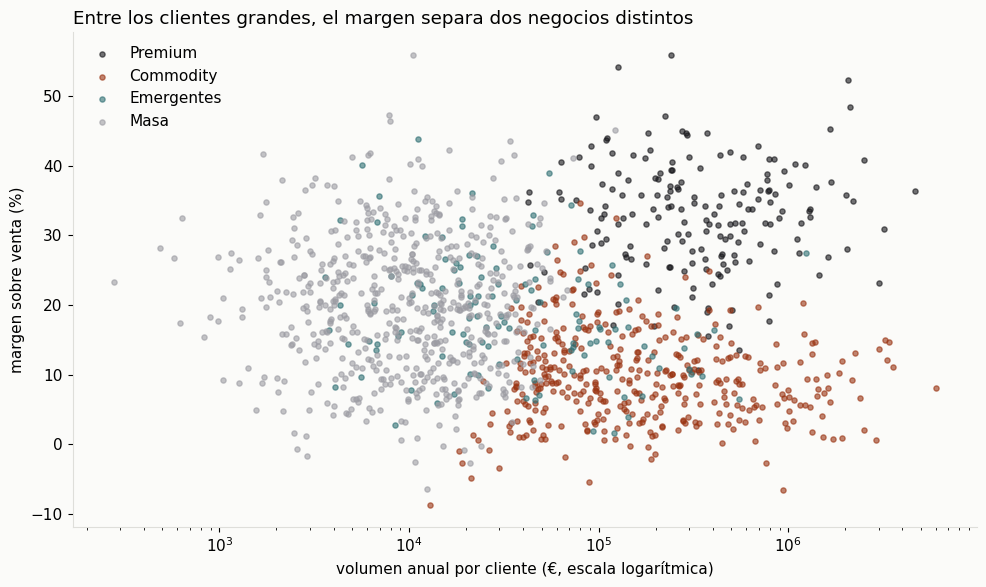

In [10]:
colores = {"Premium": TINTA, "Commodity": ACENTO, "Emergentes": "#2f6f73", "Masa": "#9c9ca3"}
fig, ax = plt.subplots(figsize=(10, 6))
for seg, color in colores.items():
    m = segmento == seg
    ax.scatter(abt.volumen[m], abt.margen_pct[m] * 100, s=14, alpha=0.6, color=color, label=seg)
ax.set_xscale("log")
ax.set_xlabel("volumen anual por cliente (€, escala logarítmica)")
ax.set_ylabel("margen sobre venta (%)")
ax.set_title("Entre los clientes grandes, el margen separa dos negocios distintos", loc="left")
ax.legend(frameon=False)
plt.tight_layout()

## 4. Reglas que ventas puede decir por teléfono

Un K-Means no se explica en una llamada. Un árbol de decisión de tres niveles traduce los
grupos a cortes en unidades de negocio (euros, pedidos, porcentaje de margen). El acierto mide
cuántos clientes clasifican bien las reglas frente a los grupos del K-Means. Es descriptivo: el
árbol aprende de las mismas variables que formaron los grupos, así que no valida el clustering.

In [11]:
arbol, acierto, texto = sg.reglas(abt, segmento)
print(f"Las reglas aciertan el grupo del {acierto:.0%} de los clientes\n")
print(texto)

Las reglas aciertan el grupo del 93% de los clientes

|--- volumen <= 36552.36
|   |--- tendencia <= 1.30
|   |   |--- margen_pct <= 0.03
|   |   |   |--- class: Masa
|   |   |--- margen_pct >  0.03
|   |   |   |--- class: Masa
|   |--- tendencia >  1.30
|   |   |--- tendencia <= 1.33
|   |   |   |--- class: Emergentes
|   |   |--- tendencia >  1.33
|   |   |   |--- class: Emergentes
|--- volumen >  36552.36
|   |--- n_categorias <= 6.50
|   |   |--- tendencia <= 1.35
|   |   |   |--- class: Commodity
|   |   |--- tendencia >  1.35
|   |   |   |--- class: Emergentes
|   |--- n_categorias >  6.50
|   |   |--- margen_pct <= 0.10
|   |   |   |--- class: Commodity
|   |   |--- margen_pct >  0.10
|   |   |   |--- class: Premium



## 5. El techo de descuento de cada grupo

El techo es el margen del grupo pesado por volumen. Una promoción de precio por encima de ese
porcentaje pierde dinero en el grupo, la acepte quien la acepte. El suelo (percentil 25 del
margen) marca un descuento con el que al menos tres de cada cuatro clientes siguen ganando.

In [12]:
techos = tc.techo_por_segmento(abt, segmento)
techos

,clientes,techo,suelo_p25,dispersion_margen,pct_volumen
segmento,,,,,
Premium,184,0.334,0.273,0.078,0.373
Commodity,394,0.089,0.054,0.066,0.560
Emergentes,124,0.167,0.136,0.084,0.036
Masa,583,0.205,0.127,0.096,0.031


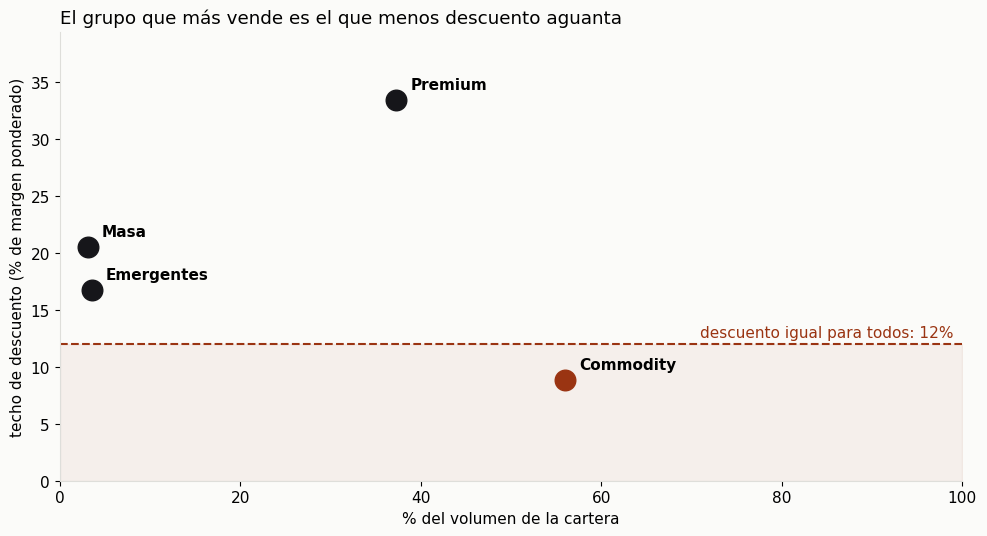

In [13]:
DESCUENTO_UNIFORME = 0.12
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.axhline(DESCUENTO_UNIFORME * 100, color=ACENTO, ls="--", lw=1.5)
ax.fill_between([0, 100], 0, DESCUENTO_UNIFORME * 100, color=ACENTO, alpha=0.06)
ax.text(99, DESCUENTO_UNIFORME * 100 + 0.6, f"descuento igual para todos: {DESCUENTO_UNIFORME:.0%}",
        color=ACENTO, ha="right")
for seg, fila in techos.iterrows():
    xv, yv = fila.pct_volumen * 100, fila.techo * 100
    ax.scatter(xv, yv, s=220, color=ACENTO if yv < DESCUENTO_UNIFORME * 100 else TINTA, zorder=3)
    ax.annotate(seg, (xv, yv), xytext=(10, 8), textcoords="offset points", weight="bold")
ax.set_xlim(0, 100)
ax.set_ylim(0, techos.techo.max() * 100 + 6)
ax.set_xlabel("% del volumen de la cartera")
ax.set_ylabel("techo de descuento (% de margen ponderado)")
ax.set_title("El grupo que más vende es el que menos descuento aguanta", loc="left")
plt.tight_layout()

In [14]:
print("Parte de los clientes de cada grupo con margen propio por debajo del descuento uniforme:")
tc.bajo_el_agua(abt, segmento, DESCUENTO_UNIFORME).round(2)

Parte de los clientes de cada grupo con margen propio por debajo del descuento uniforme:


segmento
Premium      0.010
Commodity    0.680
Emergentes   0.210
Masa         0.230
Name: margen_pct, dtype: float64

## 6. Qué hacer con cada grupo

La rejilla cruza cada grupo con su cuartil de volumen y aplica dos umbrales que decide negocio,
no el modelo: el techo mínimo para que una oferta de precio tenga hueco y el volumen mínimo para
que compense gestionarla.

In [15]:
tc.rejilla(abt, segmento, desc_min=0.06, vol_min=2_000)

,segmento,cuartil,clientes,techo,volumen_mediano,accion
0,Premium,Q1,46,0.332,"105,366.510",Promoción de precio viable
1,Premium,Q2,46,0.340,"240,505.385",Promoción de precio viable
2,Premium,Q3,46,0.297,"440,518.980",Promoción de precio viable
3,Premium,Q4,46,0.346,"978,768.475",Promoción de precio viable
4,Commodity,Q1,99,0.105,"44,795.770",Promoción de precio viable
5,Commodity,Q2,98,0.113,"90,988.840",Promoción de precio viable
6,Commodity,Q3,98,0.094,"214,639.080",Promoción de precio viable
7,Commodity,Q4,99,0.085,"855,311.490",Promoción de precio viable
8,Emergentes,Q1,31,0.206,"8,479.580",Promoción de precio viable
9,Emergentes,Q2,31,0.206,"20,921.040",Promoción de precio viable


## 7. El rappel por crecimiento

En vez de descontar sobre todo lo que compra el cliente, se descuenta solo sobre lo que crece:
"si me compras un 6 % más de lo que ya me compras, te descuento un d % sobre lo que crezcas". La
matriz da el neto para el grupo con distintos descuentos y tasas de aceptación. El signo lo
decide el descuento frente al techo; la aceptación solo cambia el tamaño.

In [16]:
for grupo in ("Premium", "Commodity"):
    print(f"{grupo}: techo {techos.loc[grupo, 'techo']:.1%}. Neto del rappel en € (u = 6 %)")
    print(tc.escenarios(abt, segmento, grupo).round(0), end="\n\n")

Premium: techo 33.4%. Neto del rappel en € (u = 6 %)
            r=15%       r=30%       r=45%         r=60%
d=4%  257,575.000 515,149.000 772,724.000 1,030,298.000
d=8%  222,547.000 445,093.000 667,640.000   890,186.000
d=12% 187,519.000 375,037.000 562,556.000   750,074.000
d=16% 152,490.000 304,981.000 457,471.000   609,962.000

Commodity: techo 8.9%. Neto del rappel en € (u = 6 %)
            r=15%        r=30%        r=45%        r=60%
d=4%   64,136.000  128,273.000  192,409.000  256,546.000
d=8%   11,507.000   23,013.000   34,520.000   46,026.000
d=12% -41,123.000  -82,247.000 -123,370.000 -164,493.000
d=16% -93,753.000 -187,506.000 -281,260.000 -375,013.000



## 8. Lo que estos datos no pueden decir

La factura dice quién compró y con qué descuento. No dice a quién se le ofreció la promoción y
no compró, ni si el descuento venía de un rappel o de un precio rebajado. Con eso se calcula el
techo, que no depende de la aceptación, pero no el efecto real de una campaña. Para medirlo
hace falta un piloto: apuntar antes de lanzar a quién se le ofrece y dejar fuera, al azar, una
parte de cada grupo como control.